# Experiment 10: Complete ANN Classification System

**Objective:** To design, train, and evaluate a complete Artificial Neural Network-based classification system using Python and Keras/TensorFlow by integrating input features, hidden layers, activation functions, training, and model evaluation.

## Theory

This final experiment brings everything from Experiments 1–9 together into one complete, end-to-end pipeline:

1. Load & explore the dataset
2. Preprocess data (train/test split, feature scaling)
3. Design the ANN architecture (input, hidden layers, activations)
4. Compile the model (optimizer, loss function)
5. Train the model (forward pass + backpropagation + gradient descent, handled internally by Keras)
6. Evaluate performance (accuracy, precision, recall, F1, confusion matrix)
7. Visualize training progress (loss & accuracy curves)
8. Make predictions on new, unseen samples

We use the **Breast Cancer Wisconsin dataset** (built into scikit-learn) — a real, binary medical classification problem: predicting whether a tumor is malignant or benign from 30 numeric features.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
)
from tensorflow import keras
from tensorflow.keras import layers

data = load_breast_cancer()
X, y = data.data, data.target
class_names = data.target_names

print(f"Dataset : Breast Cancer Wisconsin")
print(f"Samples : {X.shape[0]}   Features: {X.shape[1]}   Classes: {len(class_names)}")


Dataset : Breast Cancer Wisconsin
Samples : 569   Features: 30   Classes: 2


## Step 2: Preprocess (Split + Scale)

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(f"Training samples: {X_train.shape[0]}   Testing samples: {X_test.shape[0]}")


Training samples: 455   Testing samples: 114


## Step 3 & 4: Design and Compile the ANN

In [3]:
def build_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(16, activation="relu", name="hidden_layer_1"),
        layers.Dense(8, activation="relu", name="hidden_layer_2"),
        layers.Dense(1, activation="sigmoid", name="output_layer"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = build_model(input_dim=X.shape[1])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Train the Model

In [4]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=60,
    batch_size=16,
    verbose=0,
)
print("Training complete.")


Training complete.


## Step 6: Evaluate Performance

In [5]:
y_pred_probs = model.predict(X_test, verbose=0).ravel()
y_pred = (y_pred_probs >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nConfusion Matrix:")
print(f"                 Predicted {class_names[0]:<10} Predicted {class_names[1]}")
print(f"Actual {class_names[0]:<10}   {cm[0][0]:<20} {cm[0][1]}")
print(f"Actual {class_names[1]:<10}   {cm[1][0]:<20} {cm[1][1]}")

print()
print(classification_report(y_test, y_pred, target_names=class_names))


Accuracy  : 95.61%
Precision : 0.9855
Recall    : 0.9444
F1-Score  : 0.9645

Confusion Matrix:
                 Predicted malignant  Predicted benign
Actual malignant    41                   1
Actual benign       4                    68

              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


## Step 7: Visualize Training Progress

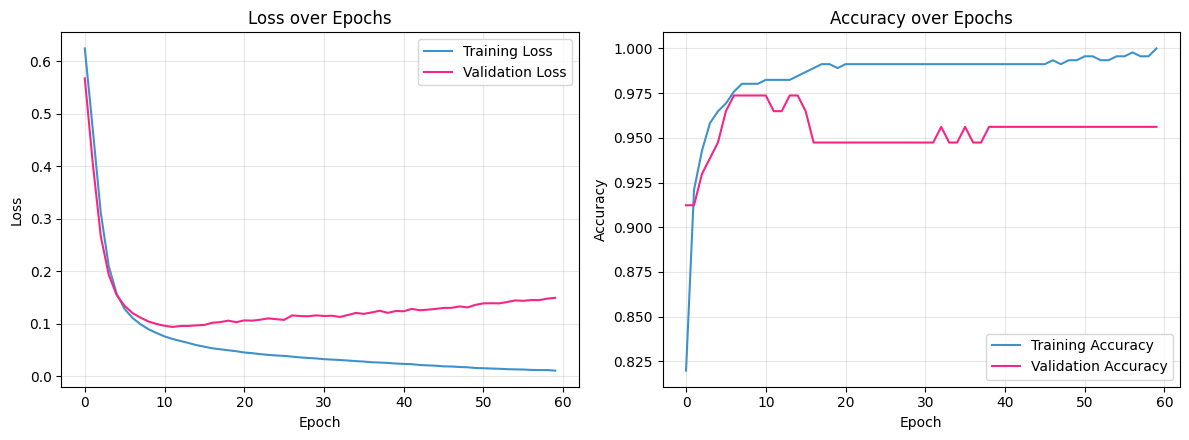

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history.history["loss"], label="Training Loss", color="#3E92CC")
axes[0].plot(history.history["val_loss"], label="Validation Loss", color="#F72585")
axes[0].set_title("Loss over Epochs"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Training Accuracy", color="#3E92CC")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy", color="#F72585")
axes[1].set_title("Accuracy over Epochs"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Step 8: Predictions on Unseen Samples

In [7]:
print(f"{'Predicted Prob':>15} | {'Predicted Class':>16} | {'Actual Class'}")
print("-" * 55)
for i in range(5):
    prob = y_pred_probs[i]
    pred_class = class_names[y_pred[i]]
    actual_class = class_names[y_test[i]]
    print(f"{prob:>15.4f} | {pred_class:>16} | {actual_class}")


 Predicted Prob |  Predicted Class | Actual Class
-------------------------------------------------------
         0.0000 |        malignant | malignant
         1.0000 |           benign | benign
         0.0000 |        malignant | malignant
         0.0623 |        malignant | benign
         0.0000 |        malignant | malignant


## Conclusion

This pipeline integrates every concept from Experiments 1–9 (neurons, weights & bias, activation functions, layered architecture, gradient descent, backpropagation, training, and evaluation) into one complete, working ANN classification system, achieving strong accuracy on a real medical dataset.